## 1. Import Necessary Libraries

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score
from datetime import datetime

## 2. Import Dataset

In [2]:
creditCard_data = pd.read_csv(filepath_or_buffer="data/credit_card_clean.csv")

## 3. Data Understanding

### Exploring the variable
* ID : ID of each client

* LIMIT_BAL: Amount of given credit in NT dollars (includes individual and family/supplementary credit)

* SEX: Gender (1=male, 2=female)

* EDUCATION: (1=graduate school, 2=university, 3=high school, 4=others, 5=unknown, 6=unknown)

* MARRIAGE: Marital status (1=married, 2=single, 3=others)

* AGE: Age in years

* PAY_1: Repayment status in September, 2005 (-2 = No consumption, -1 = paid in full, 0 = use of revolving credit (paid minimum only), 1 = payment delay for one month, 2 = payment delay for two months, ... 8 = payment delay for eight months, 9 = payment delay for nine months and above)

* PAY_2: Repayment status in August, 2005 (scale same as above)

* PAY_3: Repayment status in July, 2005 (scale same as above)

* PAY_4: Repayment status in June, 2005 (scale same as above)

* PAY_5: Repayment status in May, 2005 (scale same as above)

* PAY_6: Repayment status in April, 2005 (scale same as above)

* BILL_AMT1: Amount of bill statement in September, 2005 (NT dollar)

* BILL_AMT2: Amount of bill statement in August, 2005 (NT dollar)

* BILL_AMT3: Amount of bill statement in July, 2005 (NT dollar)

* BILL_AMT4: Amount of bill statement in June, 2005 (NT dollar)

* BILL_AMT5: Amount of bill statement in May, 2005 (NT dollar)

* BILL_AMT6: Amount of bill statement in April, 2005 (NT dollar)

* PAY_AMT1: Amount of previous payment in September, 2005 (NT dollar)

* PAY_AMT2: Amount of previous payment in August, 2005 (NT dollar)

* PAY_AMT3: Amount of previous payment in July, 2005 (NT dollar)

* PAY_AMT4: Amount of previous payment in June, 2005 (NT dollar)

* PAY_AMT5: Amount of previous payment in May, 2005 (NT dollar)

* PAY_AMT6: Amount of previous payment in April, 2005 (NT dollar)

#### Target variable
default.payment.next.month: Default payment (1=yes, 0=no)

###### Note: NT is Taiwain Dollars

In [3]:
creditCard_data.isna().sum()

ID           0
LIMIT_BAL    0
SEX          0
EDUCATION    0
MARRIAGE     0
AGE          0
PAY_1        0
PAY_2        0
PAY_3        0
PAY_4        0
PAY_5        0
PAY_6        0
BILL_AMT1    0
BILL_AMT2    0
BILL_AMT3    0
BILL_AMT4    0
BILL_AMT5    0
BILL_AMT6    0
PAY_AMT1     0
PAY_AMT2     0
PAY_AMT3     0
PAY_AMT4     0
PAY_AMT5     0
PAY_AMT6     0
DEFAULT      0
dtype: int64

In [4]:
creditCard_data.describe()

,ID,LIMIT_BAL,AGE,PAY_1,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,DEFAULT
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,...,30000.000000,30000.000000,30000.000000,30000.000000,3.000000e+04,30000.00000,30000.000000,30000.000000,30000.000000,30000.000000
mean,15000.500000,167484.322667,35.485500,-0.016700,-0.133767,-0.166200,-0.220667,-0.266200,-0.291100,51223.330900,...,43262.948967,40311.400967,38871.760400,5663.580500,5.921163e+03,5225.68150,4826.076867,4799.387633,5215.502567,0.221200
std,8660.398374,129747.661567,9.217904,1.123802,1.197186,1.196868,1.169139,1.133187,1.149988,73635.860576,...,64332.856134,60797.155770,59554.107537,16563.280354,2.304087e+04,17606.96147,15666.159744,15278.305679,17777.465775,0.415062
min,1.000000,10000.000000,21.000000,-2.000000,-2.000000,-2.000000,-2.000000,-2.000000,-2.000000,-165580.000000,...,-170000.000000,-81334.000000,-339603.000000,0.000000,0.000000e+00,0.00000,0.000000,0.000000,0.000000,0.000000
25%,7500.750000,50000.000000,28.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,3558.750000,...,2326.750000,1763.000000,1256.000000,1000.000000,8.330000e+02,390.00000,296.000000,252.500000,117.750000,0.000000
50%,15000.500000,140000.000000,34.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,22381.500000,...,19052.000000,18104.500000,17071.000000,2100.000000,2.009000e+03,1800.00000,1500.000000,1500.000000,1500.000000,0.000000
75%,22500.250000,240000.000000,41.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,67091.000000,...,54506.000000,50190.500000,49198.250000,5006.000000,5.000000e+03,4505.00000,4013.250000,4031.500000,4000.000000,0.000000
max,30000.000000,1000000.000000,79.000000,8.000000,8.000000,8.000000,8.000000,8.000000,8.000000,964511.000000,...,891586.000000,927171.000000,961664.000000,873552.000000,1.684259e+06,896040.00000,621000.000000,426529.000000,528666.000000,1.000000


In [5]:
creditCard_data.describe(include="all")

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,DEFAULT
count,30000.000000,30000.000000,30000,30000,30000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,...,30000.000000,30000.000000,30000.000000,30000.000000,3.000000e+04,30000.00000,30000.000000,30000.000000,30000.000000,30000.000000
unique,NaN,NaN,2,4,3,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,NaN,female,university,single,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,NaN,18112,14030,15964,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,15000.500000,167484.322667,NaN,NaN,NaN,35.485500,-0.016700,-0.133767,-0.166200,-0.220667,...,43262.948967,40311.400967,38871.760400,5663.580500,5.921163e+03,5225.68150,4826.076867,4799.387633,5215.502567,0.221200
std,8660.398374,129747.661567,NaN,NaN,NaN,9.217904,1.123802,1.197186,1.196868,1.169139,...,64332.856134,60797.155770,59554.107537,16563.280354,2.304087e+04,17606.96147,15666.159744,15278.305679,17777.465775,0.415062
min,1.000000,10000.000000,NaN,NaN,NaN,21.000000,-2.000000,-2.000000,-2.000000,-2.000000,...,-170000.000000,-81334.000000,-339603.000000,0.000000,0.000000e+00,0.00000,0.000000,0.000000,0.000000,0.000000
25%,7500.750000,50000.000000,NaN,NaN,NaN,28.000000,-1.000000,-1.000000,-1.000000,-1.000000,...,2326.750000,1763.000000,1256.000000,1000.000000,8.330000e+02,390.00000,296.000000,252.500000,117.750000,0.000000
50%,15000.500000,140000.000000,NaN,NaN,NaN,34.000000,0.000000,0.000000,0.000000,0.000000,...,19052.000000,18104.500000,17071.000000,2100.000000,2.009000e+03,1800.00000,1500.000000,1500.000000,1500.000000,0.000000
75%,22500.250000,240000.000000,NaN,NaN,NaN,41.000000,0.000000,0.000000,0.000000,0.000000,...,54506.000000,50190.500000,49198.250000,5006.000000,5.000000e+03,4505.00000,4013.250000,4031.500000,4000.000000,0.000000


In [6]:
creditCard_data.dtypes

ID             int64
LIMIT_BAL    float64
SEX              str
EDUCATION        str
MARRIAGE         str
AGE            int64
PAY_1          int64
PAY_2          int64
PAY_3          int64
PAY_4          int64
PAY_5          int64
PAY_6          int64
BILL_AMT1    float64
BILL_AMT2    float64
BILL_AMT3    float64
BILL_AMT4    float64
BILL_AMT5    float64
BILL_AMT6    float64
PAY_AMT1     float64
PAY_AMT2     float64
PAY_AMT3     float64
PAY_AMT4     float64
PAY_AMT5     float64
PAY_AMT6     float64
DEFAULT        int64
dtype: object

In [7]:
creditCard_data.shape

(30000, 25)

## 4. Data Preperation

In [8]:
creditCard_data.columns.tolist()

['ID',
 'LIMIT_BAL',
 'SEX',
 'EDUCATION',
 'MARRIAGE',
 'AGE',
 'PAY_1',
 'PAY_2',
 'PAY_3',
 'PAY_4',
 'PAY_5',
 'PAY_6',
 'BILL_AMT1',
 'BILL_AMT2',
 'BILL_AMT3',
 'BILL_AMT4',
 'BILL_AMT5',
 'BILL_AMT6',
 'PAY_AMT1',
 'PAY_AMT2',
 'PAY_AMT3',
 'PAY_AMT4',
 'PAY_AMT5',
 'PAY_AMT6',
 'DEFAULT']

In [9]:
creditCard_data = creditCard_data.drop(labels=["ID"], axis=1)

In [10]:
creditCard_data.sample(10)

,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,DEFAULT
15217,20000.0,female,university,single,39,0,0,0,0,0,...,16524.0,19026.0,16309.0,2000.0,2000.0,2000.0,5000.0,1000.0,6000.0,0
8023,360000.0,male,other,married,31,0,0,0,0,0,...,83359.0,85171.0,87046.0,7500.0,3500.0,2500.0,2500.0,2600.0,3000.0,0
24426,150000.0,male,grad,married,40,-2,-1,-1,-1,0,...,35206.0,36003.0,16854.0,1003.0,1003.0,35206.0,2000.0,18158.0,189000.0,0
25037,200000.0,male,university,married,54,-1,-1,-1,-1,-1,...,6335.0,4616.0,7956.0,10120.0,7852.0,6336.0,4622.0,7956.0,5499.0,0
11466,220000.0,female,university,married,45,1,-1,0,-1,0,...,43957.0,30693.0,13264.0,6010.0,1229.0,43957.0,614.0,13264.0,700.0,0
18576,110000.0,female,grad,single,24,0,0,2,2,0,...,94480.0,90860.0,85529.0,100082.0,4200.0,0.0,3000.0,3140.0,4900.0,0
17347,180000.0,female,university,married,39,0,0,0,0,0,...,113759.0,94665.0,97134.0,5812.0,6000.0,6100.0,4000.0,4000.0,4000.0,0
20140,50000.0,female,university,married,35,1,2,2,2,2,...,10999.0,12311.0,11973.0,0.0,3000.0,0.0,1800.0,0.0,1950.0,1
25341,50000.0,female,university,single,25,0,0,-1,-1,0,...,26898.0,26911.0,26926.0,1000.0,390.0,26898.0,1000.0,1000.0,1000.0,0
14775,60000.0,male,university,single,35,1,2,0,-1,-1,...,673.0,28976.0,29719.0,0.0,1680.0,2752.0,59358.0,1231.0,1200.0,0


In [11]:
le =  LabelEncoder()
creditCard_data["SEX"] = le.fit_transform(creditCard_data["SEX"])
creditCard_data["EDUCATION"] = le.fit_transform(creditCard_data["EDUCATION"])
creditCard_data["MARRIAGE"] = le.fit_transform(creditCard_data["MARRIAGE"])

In [12]:
creditCard_data.sample(5)

,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,DEFAULT
7023,260000.0,0,3,0,42,0,0,0,0,0,...,18657.0,33296.0,32622.0,5000.0,2655.0,800.0,15000.0,0.0,10000.0,0
4261,30000.0,0,3,2,50,0,0,2,0,0,...,28763.0,29383.0,28987.0,4664.0,0.0,994.0,1047.0,1412.0,756.0,0
5189,30000.0,1,3,2,24,0,0,0,0,0,...,29121.0,29368.0,13174.0,1598.0,1599.0,928.0,600.0,627.0,1500.0,0
20404,150000.0,1,2,2,32,0,0,0,-1,0,...,150464.0,143375.0,146411.0,4019.0,146896.0,157436.0,4600.0,4709.0,5600.0,0
5910,50000.0,0,3,2,24,-1,-1,-1,-1,0,...,1055.0,102.0,2110.0,306.0,995.0,1055.0,0.0,2110.0,0.0,0


In [13]:
creditCard_data.dtypes

LIMIT_BAL    float64
SEX            int64
EDUCATION      int64
MARRIAGE       int64
AGE            int64
PAY_1          int64
PAY_2          int64
PAY_3          int64
PAY_4          int64
PAY_5          int64
PAY_6          int64
BILL_AMT1    float64
BILL_AMT2    float64
BILL_AMT3    float64
BILL_AMT4    float64
BILL_AMT5    float64
BILL_AMT6    float64
PAY_AMT1     float64
PAY_AMT2     float64
PAY_AMT3     float64
PAY_AMT4     float64
PAY_AMT5     float64
PAY_AMT6     float64
DEFAULT        int64
dtype: object

## 5. Model Building

In [14]:
X = creditCard_data.drop(labels=["DEFAULT"], axis=1)
X.head()

,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6
0,20000.0,0,3,0,24,2,2,-1,-1,-2,...,689.0,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0
1,120000.0,0,3,2,26,-1,2,0,0,0,...,2682.0,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0
2,90000.0,0,3,2,34,0,0,0,0,0,...,13559.0,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0
3,50000.0,0,3,0,37,0,0,0,0,0,...,49291.0,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0
4,50000.0,1,3,0,57,-1,0,-1,0,0,...,35835.0,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0


In [15]:
y = creditCard_data.DEFAULT
y.head()

0    1
1    1
2    0
3    0
4    0
Name: DEFAULT, dtype: int64

In [16]:
print(f"X_shape: {X.shape}")
print(f"y_shape: {y.shape}")

X_shape: (30000, 23)
y_shape: (30000,)


In [17]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=123, shuffle=True)

In [18]:
print(f"X_train: {X_train.shape}")
print(f"X_test: {X_test.shape}")
print(f"y_train: {y_train.shape}")
print(f"y_test: {y_test.shape}")

X_train: (24000, 23)
X_test: (6000, 23)
y_train: (24000,)
y_test: (6000,)


## 6. Model Training

#### Training Time Analyss

In [19]:
adb_classifier = AdaBoostClassifier(n_estimators=100)
gb_classifier = GradientBoostingClassifier(n_estimators=100)
XGBM_classifier = XGBClassifier(n_estimators=100)
LGBM_classifier = LGBMClassifier(n_estimators=100)

In [20]:
%%time
adb_classifier.fit(X_train, y_train)
print()


CPU times: total: 2.03 s
Wall time: 2.02 s


In [21]:
%%time
gb_classifier.fit(X_train, y_train)
print()


CPU times: total: 4.61 s
Wall time: 4.65 s


In [22]:
%%time
XGBM_classifier.fit(X_train, y_train)
print()


CPU times: total: 1.8 s
Wall time: 197 ms


In [23]:
%%time
LGBM_classifier.fit(X_train, y_train)
print()

[LightGBM] [Info] Number of positive: 5309, number of negative: 18691
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001817 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3259
[LightGBM] [Info] Number of data points in the train set: 24000, number of used features: 23
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.221208 -> initscore=-1.258639
[LightGBM] [Info] Start training from score -1.258639

CPU times: total: 3.67 s
Wall time: 1.36 s


## 7. Model Testing

In [24]:
# y_pred_train_adb = adb_classifier.predict(X_train)
# y_pred_train_gb = gb_classifier.predict(X_train)
# y_pred_train_xgbm = XGBM_classifier.predict(X_train)
# y_pred_train_lgbm = LGBM_classifier.predict(X_train)

In [25]:
y_pred_test_adb = adb_classifier.predict(X_test)
y_pred_test_gb = gb_classifier.predict(X_test)
y_pred_test_xgbm = XGBM_classifier.predict(X_test)
y_pred_test_lgbm = LGBM_classifier.predict(X_test)

## 8. Model Evaluation

In [26]:
print(f"Accuracy Score:")
print(f"--------------------")
print(f"ADA_Boost: {accuracy_score(y_test, y_pred_test_adb)}")
print(f"GB: {accuracy_score(y_test, y_pred_test_gb)}")
print(f"XGBM: {accuracy_score(y_test, y_pred_test_xgbm)}")
print(f"LGBM: {accuracy_score(y_test, y_pred_test_lgbm)}")
print(f"==============================================================")
print(f"")
print(f"Precision Score:")
print(f"--------------------")
print(f"ADA_Boost: {precision_score(y_test, y_pred_test_adb)}")
print(f"GB: {precision_score(y_test, y_pred_test_gb)}")
print(f"XGBM: {precision_score(y_test, y_pred_test_xgbm)}")
print(f"LGBM: {precision_score(y_test, y_pred_test_lgbm)}")
print(f"==============================================================")
print(f"")
print(f"Recall Score:")
print(f"--------------------")
print(f"ADA_Boost: {recall_score(y_test, y_pred_test_adb)}")
print(f"GB: {recall_score(y_test, y_pred_test_gb)}")
print(f"XGBM: {recall_score(y_test, y_pred_test_xgbm)}")
print(f"LGBM: {recall_score(y_test, y_pred_test_lgbm)}")
print(f"==============================================================")
print(f"")
print(f"Confustion Matrix:")
print(f"--------------------")
print(f"ADA_Boost: \n{confusion_matrix(y_test, y_pred_test_adb)}")
print(f"----------------------------")
print(f"GB: \n{confusion_matrix(y_test, y_pred_test_gb)}")
print(f"----------------------------")
print(f"XGBM: \n{confusion_matrix(y_test, y_pred_test_xgbm)}")
print(f"----------------------------")
print(f"LGBM: \n{confusion_matrix(y_test, y_pred_test_lgbm)}")
print(f"----------------------------")

Accuracy Score:
--------------------
ADA_Boost: 0.8208333333333333
GB: 0.8228333333333333
XGBM: 0.8158333333333333
LGBM: 0.825

Precision Score:
--------------------
ADA_Boost: 0.7
GB: 0.6907514450867052
XGBM: 0.6520547945205479
LGBM: 0.698140200286123

Recall Score:
--------------------
ADA_Boost: 0.33232856066315
GB: 0.3602110022607385
XGBM: 0.35870384325546345
LGBM: 0.3677467972871138

Confustion Matrix:
--------------------
ADA_Boost: 
[[4484  189]
 [ 886  441]]
----------------------------
GB: 
[[4459  214]
 [ 849  478]]
----------------------------
XGBM: 
[[4419  254]
 [ 851  476]]
----------------------------
LGBM: 
[[4462  211]
 [ 839  488]]
----------------------------


In [27]:
print(f"ADA Boost:")
print(f"-------------")
print(f"Accuracy Score: {accuracy_score(y_test, y_pred_test_adb):.3%}")
print(f"Precision Score: {precision_score(y_test, y_pred_test_adb):.3%}")
print(f"Recall Score: {recall_score(y_test, y_pred_test_adb):.3%}")
print(f"Confusion Matrix:\n{confusion_matrix(y_test, y_pred_test_adb)}")
print(f"==============================================================")
print(f"")
print(f"GB Boost:")
print(f"-------------")
print(f"Accuracy Score: {accuracy_score(y_test, y_pred_test_gb):.3%}")
print(f"Precision Score: {precision_score(y_test, y_pred_test_gb):.3%}")
print(f"Recall Score: {recall_score(y_test, y_pred_test_gb):.3%}")
print(f"Confusion Matrix:\n{confusion_matrix(y_test, y_pred_test_gb)}")
print(f"==============================================================")
print(f"")
print(f"XGBM Boost:")
print(f"-------------")
print(f"Accuracy Score: {accuracy_score(y_test, y_pred_test_xgbm):.3%}")
print(f"Precision Score: {precision_score(y_test, y_pred_test_xgbm):.3%}")
print(f"Recall Score: {recall_score(y_test, y_pred_test_xgbm):.3%}")
print(f"Confusion Matrix:\n{confusion_matrix(y_test, y_pred_test_xgbm)}")
print(f"==============================================================")
print(f"")
print(f"LGBM Boost:")
print(f"-------------")
print(f"Accuracy Score: {accuracy_score(y_test, y_pred_test_lgbm):.3%}")
print(f"Precision Score: {precision_score(y_test, y_pred_test_lgbm):.3%}")
print(f"Recall Score: {recall_score(y_test, y_pred_test_lgbm):.3%}")
print(f"Confusion Matrix:\n{confusion_matrix(y_test, y_pred_test_lgbm)}")

ADA Boost:
-------------
Accuracy Score: 82.083%
Precision Score: 70.000%
Recall Score: 33.233%
Confusion Matrix:
[[4484  189]
 [ 886  441]]

GB Boost:
-------------
Accuracy Score: 82.283%
Precision Score: 69.075%
Recall Score: 36.021%
Confusion Matrix:
[[4459  214]
 [ 849  478]]

XGBM Boost:
-------------
Accuracy Score: 81.583%
Precision Score: 65.205%
Recall Score: 35.870%
Confusion Matrix:
[[4419  254]
 [ 851  476]]

LGBM Boost:
-------------
Accuracy Score: 82.500%
Precision Score: 69.814%
Recall Score: 36.775%
Confusion Matrix:
[[4462  211]
 [ 839  488]]


---
---
---

# Feature Importance

In [52]:
feature_names = X_train.columns
print(feature_names)

Index(['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_1', 'PAY_2',
       'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2',
       'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1',
       'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6'],
      dtype='str')


In [53]:
import pandas as pd
import matplotlib.pyplot as plt

adaboost_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": adb_classifier.feature_importances_
})

gb_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": gb_classifier.feature_importances_
})

xgb_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": XGBM_classifier.feature_importances_
})

lgbm_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": LGBM_classifier.feature_importances_
})

In [54]:
adaboost_importance = adaboost_importance.sort_values(
    by="Importance", ascending=False
)

gb_importance = gb_importance.sort_values(
    by="Importance", ascending=False
)

xgb_importance = xgb_importance.sort_values(
    by="Importance", ascending=False
)

lgbm_importance = lgbm_importance.sort_values(
    by="Importance", ascending=False
)

In [55]:
comparison = pd.DataFrame({
    "Feature": X_train.columns,
    "AdaBoost": adb_classifier.feature_importances_,
    "GradientBoosting": gb_classifier.feature_importances_,
    "XGBoost": XGBM_classifier.feature_importances_,
    "LightGBM": LGBM_classifier.feature_importances_
})

comparison = comparison.set_index("Feature")

display(comparison)

,AdaBoost,GradientBoosting,XGBoost,LightGBM
Feature,,,,
LIMIT_BAL,0.046151,0.031109,0.021307,236
SEX,0.011644,0.002255,0.016453,40
EDUCATION,0.000000,0.004155,0.017921,72
MARRIAGE,0.014302,0.003174,0.019161,35
AGE,0.000000,0.007463,0.017493,217
PAY_1,0.471914,0.616491,0.391683,98
PAY_2,0.040138,0.088231,0.109953,44
PAY_3,0.047040,0.040526,0.056993,52
PAY_4,0.024340,0.015739,0.035313,36


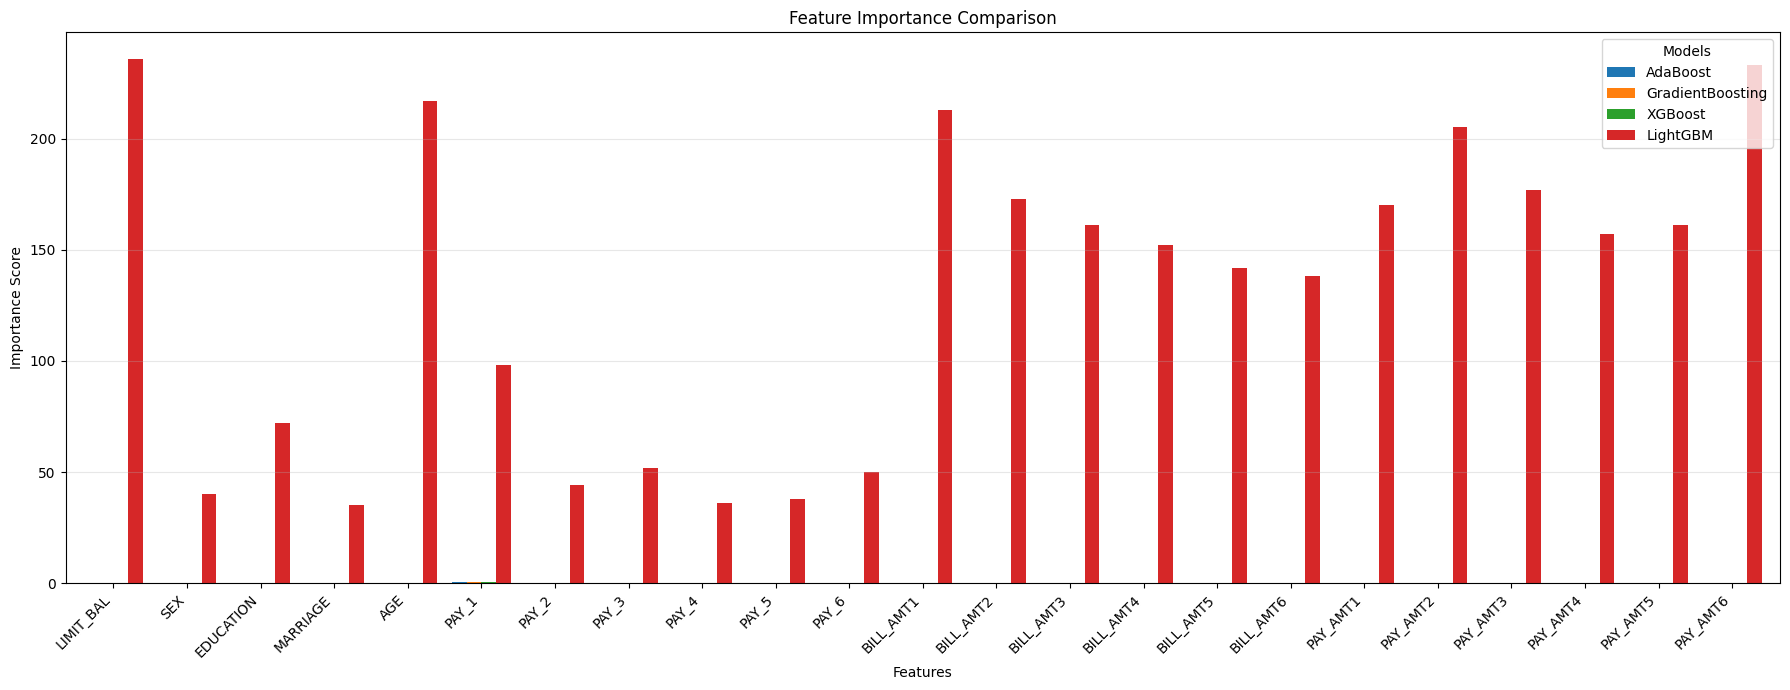

In [56]:
comparison.plot(
    kind="bar",
    figsize=(18, 7),
    width=0.8
)

plt.title("Feature Importance Comparison")
plt.ylabel("Importance Score")
plt.xlabel("Features")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Models")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [57]:
normalized_comparison = comparison.div(
    comparison.sum(axis=0),
    axis=1
) * 100

display(normalized_comparison.round(2))

,AdaBoost,GradientBoosting,XGBoost,LightGBM
Feature,,,,
LIMIT_BAL,4.62,3.11,2.13,7.87
SEX,1.16,0.23,1.65,1.33
EDUCATION,0.00,0.42,1.79,2.40
MARRIAGE,1.43,0.32,1.92,1.17
AGE,0.00,0.75,1.75,7.23
PAY_1,47.19,61.65,39.17,3.27
PAY_2,4.01,8.82,11.00,1.47
PAY_3,4.70,4.05,5.70,1.73
PAY_4,2.43,1.57,3.53,1.20


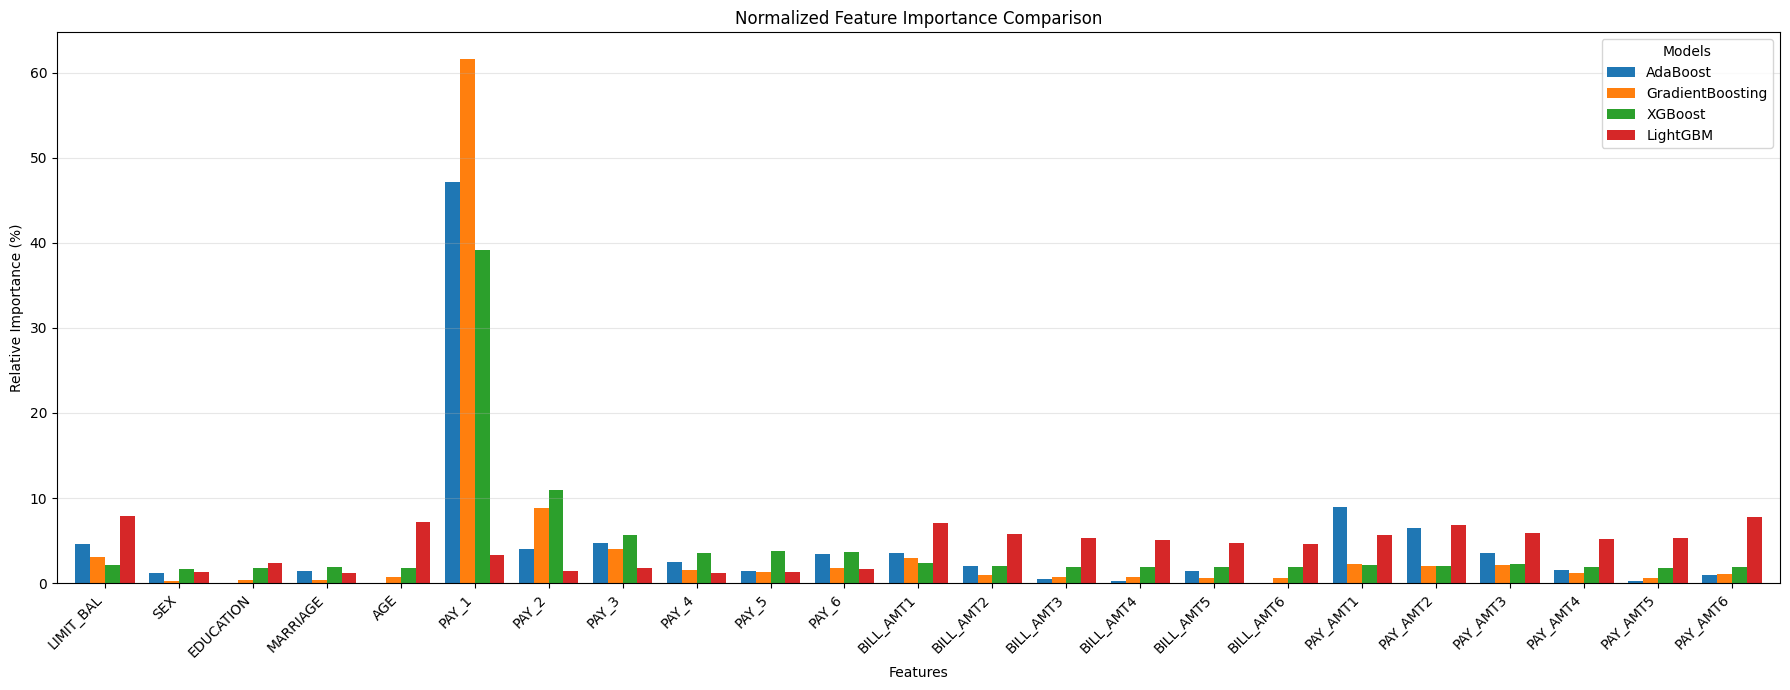

In [58]:
normalized_comparison.plot(
    kind="bar",
    figsize=(18, 7),
    width=0.8
)

plt.title("Normalized Feature Importance Comparison")
plt.ylabel("Relative Importance (%)")
plt.xlabel("Features")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Models")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [59]:
normalized_comparison["Average_Importance"] = (
    normalized_comparison.mean(axis=1)
)

normalized_comparison = normalized_comparison.sort_values(
    by="Average_Importance",
    ascending=False
)

display(normalized_comparison.round(2))

,AdaBoost,GradientBoosting,XGBoost,LightGBM,Average_Importance
Feature,,,,,
PAY_1,47.19,61.65,39.17,3.27,37.82
PAY_2,4.01,8.82,11.00,1.47,6.32
PAY_AMT1,9.01,2.28,2.18,5.67,4.79
LIMIT_BAL,4.62,3.11,2.13,7.87,4.43
PAY_AMT2,6.52,2.05,2.04,6.83,4.36
PAY_3,4.70,4.05,5.70,1.73,4.05
BILL_AMT1,3.50,2.96,2.32,7.10,3.97
PAY_AMT3,3.50,2.13,2.24,5.90,3.44
PAY_AMT6,0.97,1.04,1.93,7.77,2.93


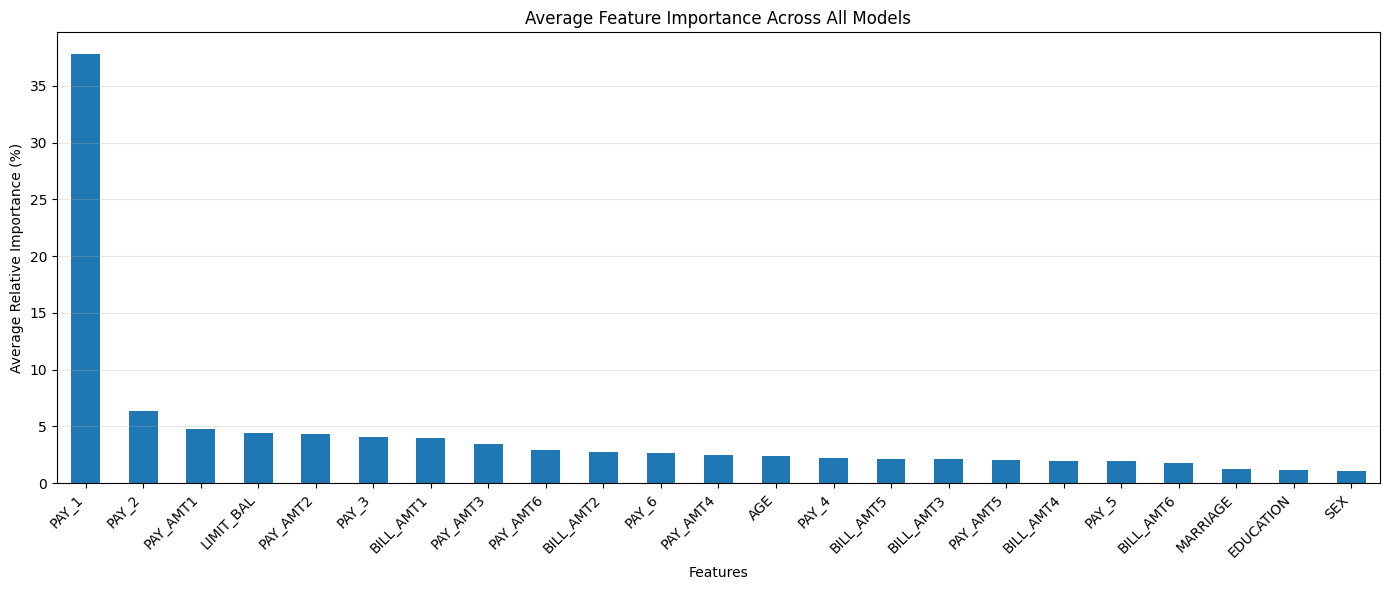

In [60]:
normalized_comparison["Average_Importance"].plot(
    kind="bar",
    figsize=(14, 6)
)

plt.title("Average Feature Importance Across All Models")
plt.ylabel("Average Relative Importance (%)")
plt.xlabel("Features")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()